# 🌳 Decision Tree Classifier — Iris Veri Seti ile Uçtan Uca Anlatım

Bu notebook'un amacı sadece model kurmak değil; **karar ağacının nasıl çalıştığını, parametrelerinin ağacı nasıl değiştirdiğini ve ağacın nasıl okunduğunu** adım adım gösterebilmek.

**İçerik**
1. Kütüphaneler ve veri seti
2. Keşifsel veri analizi (EDA)
3. Train / test ayrımı
4. İlk (temel) model
5. Ağacı okumak: `plot_tree`, `export_text`, düğüm (node) bilgileri
6. Ağaç bölünmeyi nasıl seçiyor? Gini & Entropy'yi elle hesaplamak
7. Ağacın iç yapısı: derinlik, yaprak sayısı, feature importance
8. Parametrelerin etkisi (max_depth, min_samples_split, min_samples_leaf, criterion, max_features, splitter, ccp_alpha)
9. Karar sınırlarının (decision boundary) görselleştirilmesi
10. Hiperparametre optimizasyonu (GridSearchCV)
11. Final model ve tek bir örneğin ağaçta izlediği yol
12. Özet: parametre tablosu

## 1. Kütüphaneler ve Veri Seti

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.datasets import load_iris                      # iris veri seti sklearn içinde hazır geliyor, csv'ye gerek yok
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
RANDOM_STATE = 42   # sonuçların her çalıştırmada aynı çıkması için sabit seed

In [2]:
iris = load_iris(as_frame=True)   # as_frame=True -> veriyi pandas DataFrame olarak döndürür

df = iris.frame.copy()
# hedef değişken 0,1,2 şeklinde sayısal geliyor; okunabilirlik için tür isimlerini de ekliyoruz
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))

feature_names = iris.feature_names        # ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
class_names = list(iris.target_names)     # ['setosa', 'versicolor', 'virginica']

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## 2. Keşifsel Veri Analizi (EDA)
- 150 örnek, 4 sayısal özellik (çanak/taç yaprak uzunluk ve genişlikleri), 3 sınıf.
- Karar ağaçları **ölçeklemeye (StandardScaler vb.) ihtiyaç duymaz**, çünkü her bölünme tek bir özellik üzerinde "≤ eşik" sorusudur. Özelliğin birimi/ölçeği sonucu değiştirmez.

In [3]:
df.info()                                  # eksik değer var mı, veri tipleri ne?

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   target             150 non-null    int64  
 5   species            150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 7.2 KB


In [4]:
df["species"].value_counts()               # sınıflar dengeli mi? (her sınıftan 50 örnek -> dengeli)

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [5]:
df.describe().T                            # özelliklerin min / max / ortalama değerleri

,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5
target,150.0,1.000000,0.819232,0.0,0.0,1.00,2.0,2.0


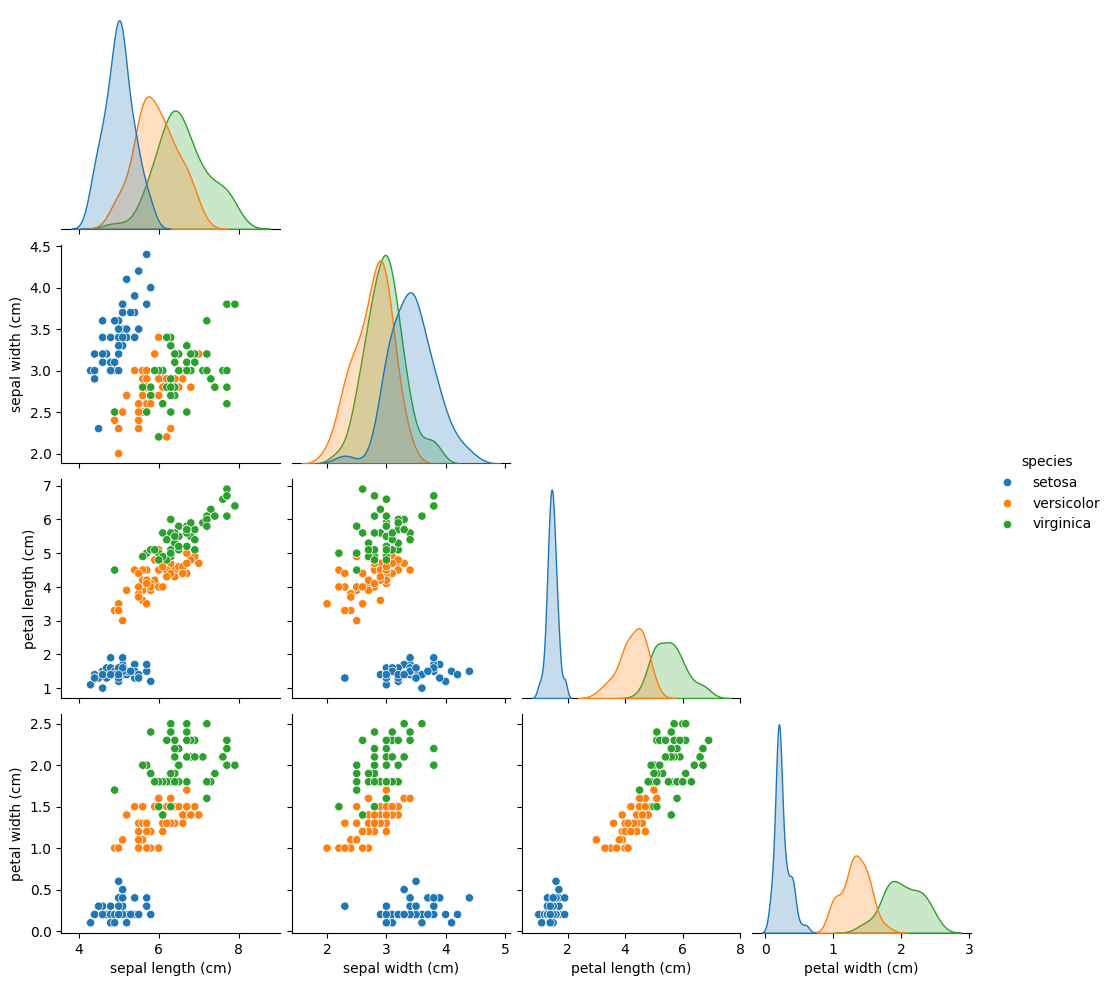

In [6]:
# Pairplot: her özellik çiftinin dağılımı. Petal özelliklerinin sınıfları çok iyi ayırdığı burada görülüyor.
# Ağacın ilk bölünmeyi neden petal üzerinden yaptığını anlatırken bu grafik iyi bir giriş olur.
sns.pairplot(df.drop(columns="target"), hue="species", corner=True)
plt.show()

## 3. Train / Test Ayrımı

In [7]:
X = df[feature_names]
y = df["target"]

# stratify=y -> train ve test setlerinde sınıf oranları korunur (her sınıftan eşit oranda örnek)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train sınıf dağılımı:", np.bincount(y_train))

Train: (112, 4)  Test: (38, 4)
Train sınıf dağılımı: [38 37 37]


## 4. İlk (Temel) Model
Hiçbir parametre vermezsek ağaç **saf (pure) yapraklara ulaşana kadar** büyür → train setini ezberleyebilir (overfitting).

In [8]:
# Varsayılan parametreler: criterion="gini", max_depth=None, min_samples_split=2, min_samples_leaf=1
default_tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
default_tree.fit(X_train, y_train)

print("Train accuracy:", accuracy_score(y_train, default_tree.predict(X_train)))   # genelde 1.0 -> ezber işareti
print("Test  accuracy:", accuracy_score(y_test,  default_tree.predict(X_test)))
print("Derinlik:", default_tree.get_depth(), "| Yaprak sayısı:", default_tree.get_n_leaves())

Train accuracy: 1.0
Test  accuracy: 0.8947368421052632
Derinlik: 6 | Yaprak sayısı: 9


In [9]:
# Daha sade bir model: derinliği 3 ile sınırlıyoruz (anlatım için okunması kolay bir ağaç)
model = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=RANDOM_STATE)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("-" * 60)
print(classification_report(y_test, y_pred, target_names=class_names))

Accuracy: 0.8947368421052632
------------------------------------------------------------
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.80      0.92      0.86        13
   virginica       0.91      0.77      0.83        13

    accuracy                           0.89        38
   macro avg       0.90      0.90      0.90        38
weighted avg       0.90      0.89      0.89        38



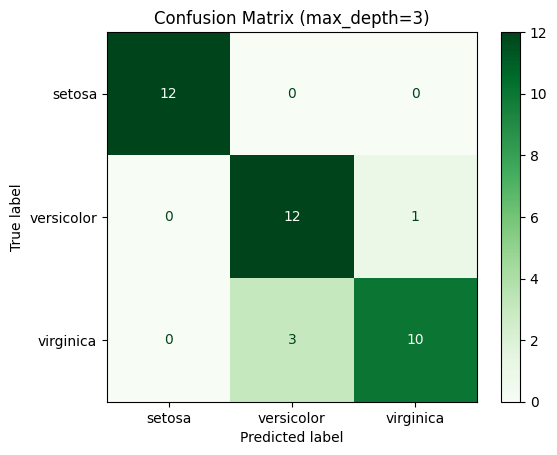

In [10]:
# Confusion matrix: satırlar gerçek sınıf, sütunlar tahmin edilen sınıf
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=class_names, cmap="Greens")
plt.title("Confusion Matrix (max_depth=3)")
plt.show()

## 5. Ağacı Okumak

Her kutu (node) şunları gösterir:

| Satır | Anlamı |
|---|---|
| `petal length (cm) <= 2.45` | Bölünme sorusu. **Doğru (True) → sol**, **Yanlış (False) → sağ** dal |
| `gini = 0.667` | Düğümün safsızlığı (impurity). 0 = tamamen saf (tek sınıf) |
| `samples = 112` | Bu düğüme düşen train örneği sayısı |
| `value = [37, 37, 38]` | Bu düğümdeki örneklerin sınıflara göre dağılımı |
| `class = virginica` | Bu düğümde çoğunluk sınıfı → yaprak ise tahmin budur |

Renk: sınıfı, rengin koyuluğu: düğümün ne kadar saf olduğunu gösterir.

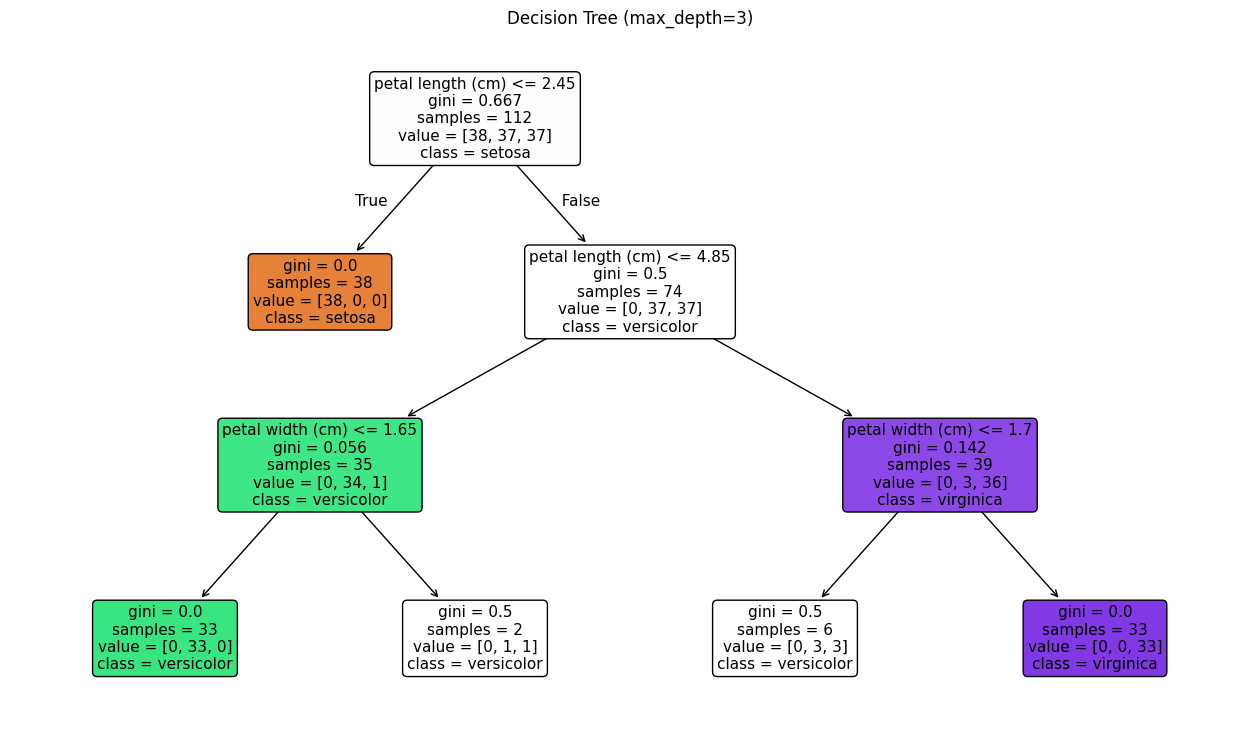

In [11]:
plt.figure(figsize=(16, 9))
plot_tree(
    model,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,        # düğümleri çoğunluk sınıfına göre renklendir
    rounded=True,       # köşeleri yuvarlat
    impurity=True,      # gini/entropy değerini göster
    proportion=False,   # True olursa samples/value oran olarak gösterilir
    fontsize=11
)
plt.title("Decision Tree (max_depth=3)")
plt.show()

In [12]:
# Aynı ağacın metin hali: if-else kuralları gibi okunabilir. Sunumda kuralları anlatmak için çok kullanışlı.
print(export_text(model, feature_names=feature_names, show_weights=True))

|--- petal length (cm) <= 2.45
|   |--- weights: [38.00, 0.00, 0.00] class: 0
|--- petal length (cm) >  2.45
|   |--- petal length (cm) <= 4.85
|   |   |--- petal width (cm) <= 1.65
|   |   |   |--- weights: [0.00, 33.00, 0.00] class: 1
|   |   |--- petal width (cm) >  1.65
|   |   |   |--- weights: [0.00, 1.00, 1.00] class: 1
|   |--- petal length (cm) >  4.85
|   |   |--- petal width (cm) <= 1.70
|   |   |   |--- weights: [0.00, 3.00, 3.00] class: 1
|   |   |--- petal width (cm) >  1.70
|   |   |   |--- weights: [0.00, 0.00, 33.00] class: 2



## 6. Ağaç Bölünmeyi Nasıl Seçiyor? (Gini & Entropy)

Ağaç her düğümde **tüm özellikleri ve tüm olası eşikleri** dener; çocuk düğümlerin ağırlıklı safsızlığını en çok düşüren bölünmeyi seçer.

**Gini:** $\;G = 1 - \sum_k p_k^2$  
**Entropy:** $\;H = -\sum_k p_k \log_2 p_k$  
**Kazanç (Information Gain):** $\;\text{Parent} - \left(\frac{n_L}{n} \cdot \text{Left} + \frac{n_R}{n} \cdot \text{Right}\right)$

Aşağıda kök düğümün bölünmesini **elle** hesaplayıp ağacın bulduğu sonuçla karşılaştırıyoruz.

In [13]:
def gini(labels):
    """Gini safsızlığı: 1 - sum(p_k^2)"""
    _, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()
    return 1 - np.sum(p ** 2)

def entropy(labels):
    """Entropi: -sum(p_k * log2(p_k))"""
    _, counts = np.unique(labels, return_counts=True)
    p = counts / counts.sum()
    return -np.sum(p * np.log2(p))

print("Kök düğüm gini   :", round(gini(y_train), 4))     # plot_tree'deki ilk kutudaki gini ile aynı olmalı
print("Kök düğüm entropy:", round(entropy(y_train), 4))

Kök düğüm gini   : 0.6666
Kök düğüm entropy: 1.5848


In [14]:
def best_split(X, y, impurity_fn=gini):
    """Tüm özellikler ve tüm eşikler için ağırlıklı çocuk safsızlığını hesaplar, en iyisini döndürür."""
    parent = impurity_fn(y)
    results = []
    for feat in X.columns:
        values = np.sort(X[feat].unique())
        thresholds = (values[:-1] + values[1:]) / 2      # sklearn de eşikleri ardışık değerlerin ortası olarak seçer
        for t in thresholds:
            left, right = y[X[feat] <= t], y[X[feat] > t]
            weighted = (len(left) * impurity_fn(left) + len(right) * impurity_fn(right)) / len(y)
            results.append((feat, t, weighted, parent - weighted))
    res = pd.DataFrame(results, columns=["feature", "threshold", "weighted_child_impurity", "gain"])
    return res.sort_values("gain", ascending=False)

splits = best_split(X_train, y_train)
splits.head(5)   # en çok kazanç sağlayan 5 bölünme

,feature,threshold,weighted_child_impurity,gain
95,petal width (cm),0.80,0.330357,0.336256
59,petal length (cm),2.45,0.330357,0.336256
60,petal length (cm),3.25,0.343231,0.323383
94,petal width (cm),0.50,0.343571,0.323042
58,petal length (cm),1.80,0.356438,0.310176


In [15]:
# Ağacın kendi seçtiği kök bölünme ile karşılaştıralım
root_feature = feature_names[model.tree_.feature[0]]
root_threshold = model.tree_.threshold[0]
print(f"sklearn kök bölünmesi : {root_feature} <= {root_threshold:.2f}")
print(f"Elle bulunan en iyisi  : {splits.iloc[0]['feature']} <= {splits.iloc[0]['threshold']:.2f}")
# Not: petal length ve petal width setosa'yı aynı başarıyla ayırabilir (eşit kazanç).
# Bu durumda sklearn özellikleri rastgele sırayla dener; random_state hangisinin seçileceğini belirler.

sklearn kök bölünmesi : petal length (cm) <= 2.45
Elle bulunan en iyisi  : petal width (cm) <= 0.80


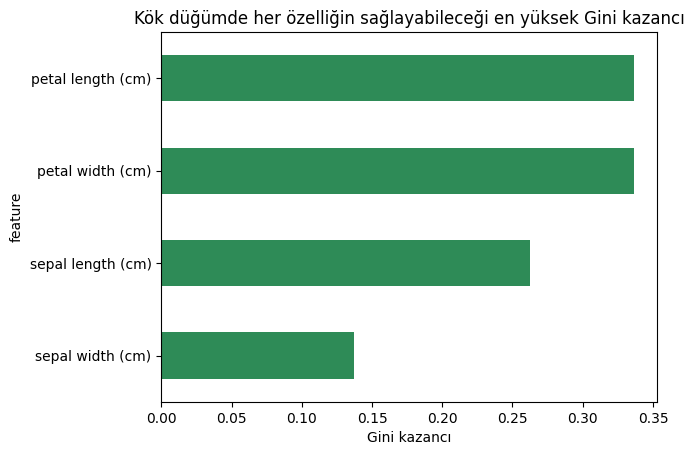

In [16]:
# Her özellik için en iyi kazancı karşılaştıralım -> hangi özellik kökte en güçlü?
best_per_feature = splits.groupby("feature")["gain"].max().sort_values()
best_per_feature.plot(kind="barh", color="seagreen")
plt.title("Kök düğümde her özelliğin sağlayabileceği en yüksek Gini kazancı")
plt.xlabel("Gini kazancı")
plt.show()

## 7. Ağacın İç Yapısı ve Feature Importance

In [17]:
t = model.tree_    # eğitilmiş ağacın düşük seviyeli yapısı

print("Toplam düğüm sayısı :", t.node_count)
print("Derinlik            :", model.get_depth())
print("Yaprak sayısı       :", model.get_n_leaves())
print("Sınıflar            :", model.classes_)

Toplam düğüm sayısı : 9
Derinlik            : 3
Yaprak sayısı       : 5
Sınıflar            : [0 1 2]


In [18]:
# Her düğümün bilgilerini tablo halinde görelim
# children_left/right == -1 ise düğüm yapraktır
nodes = pd.DataFrame({
    "node": range(t.node_count),
    "is_leaf": t.children_left == -1,
    "feature": [feature_names[f] if f >= 0 else "-" for f in t.feature],
    "threshold": np.where(t.feature >= 0, t.threshold.round(2), np.nan),
    "impurity": t.impurity.round(3),
    "samples": t.n_node_samples,
    "left_child": t.children_left,
    "right_child": t.children_right,
})
nodes

,node,is_leaf,feature,threshold,impurity,samples,left_child,right_child
0,0,False,petal length (cm),2.45,0.667,112,1,2
1,1,True,-,NaN,0.000,38,-1,-1
2,2,False,petal length (cm),4.85,0.500,74,3,6
3,3,False,petal width (cm),1.65,0.056,35,4,5
4,4,True,-,NaN,0.000,33,-1,-1
5,5,True,-,NaN,0.500,2,-1,-1
6,6,False,petal width (cm),1.70,0.142,39,7,8
7,7,True,-,NaN,0.500,6,-1,-1
8,8,True,-,NaN,0.000,33,-1,-1


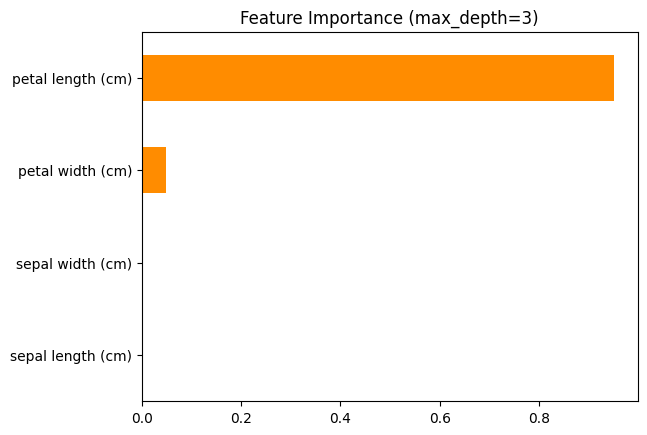

sepal length (cm)    0.000000
sepal width (cm)     0.000000
petal width (cm)     0.049268
petal length (cm)    0.950732
dtype: float64

In [19]:
# Feature importance: bir özelliğin ağaç boyunca sağladığı toplam (ağırlıklı) safsızlık azalması, normalize edilmiş hali.
# Toplamı 1'dir. Hiç bölünmede kullanılmayan özelliğin önemi 0'dır.
importances = pd.Series(model.feature_importances_, index=feature_names).sort_values()
importances.plot(kind="barh", color="darkorange")
plt.title("Feature Importance (max_depth=3)")
plt.show()
importances

## 8. Parametrelerin Ağaca Etkisi

Karar ağacının en önemli parametreleri iki gruba ayrılır:
- **Bölünme kriteri:** `criterion`, `splitter`, `max_features`
- **Ağacın büyümesini sınırlayan (pre-pruning):** `max_depth`, `min_samples_split`, `min_samples_leaf`, `max_leaf_nodes`, `min_impurity_decrease`
- **Sonradan budama (post-pruning):** `ccp_alpha`

Her parametreyi tek tek değiştirip train/test başarısını ve ağaç boyutunu izleyeceğiz.

In [20]:
def evaluate(param_name, values, **fixed):
    """Bir parametrenin farklı değerleri için train/test/CV başarısı ve ağaç boyutunu döndürür."""
    rows = []
    for v in values:
        clf = DecisionTreeClassifier(random_state=RANDOM_STATE, **{param_name: v}, **fixed)
        clf.fit(X_train, y_train)
        rows.append({
            param_name: str(v),
            "train_acc": accuracy_score(y_train, clf.predict(X_train)),
            "test_acc": accuracy_score(y_test, clf.predict(X_test)),
            "cv_acc": cross_val_score(clf, X_train, y_train, cv=5).mean(),  # 5-fold CV -> daha güvenilir tahmin
            "depth": clf.get_depth(),
            "leaves": clf.get_n_leaves(),
        })
    return pd.DataFrame(rows)

def plot_eval(res, param_name, title):
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    ax[0].plot(res[param_name], res["train_acc"], "o-", label="Train")
    ax[0].plot(res[param_name], res["test_acc"], "s-", label="Test")
    ax[0].plot(res[param_name], res["cv_acc"], "^--", label="CV (5-fold)")
    ax[0].set_title(f"{title} — Başarı"); ax[0].set_xlabel(param_name); ax[0].set_ylabel("Accuracy"); ax[0].legend()
    ax[1].bar(res[param_name], res["leaves"], color="steelblue")
    ax[1].set_title(f"{title} — Yaprak sayısı"); ax[1].set_xlabel(param_name)
    plt.tight_layout(); plt.show()

### 8.1 `max_depth` — Maksimum derinlik
Kökten en uzak yaprağa kadar en fazla kaç soru sorulabileceği.  
- Küçük → **underfitting** (model çok basit)  
- Büyük / `None` → **overfitting** (train=1.0 ama test düşebilir)

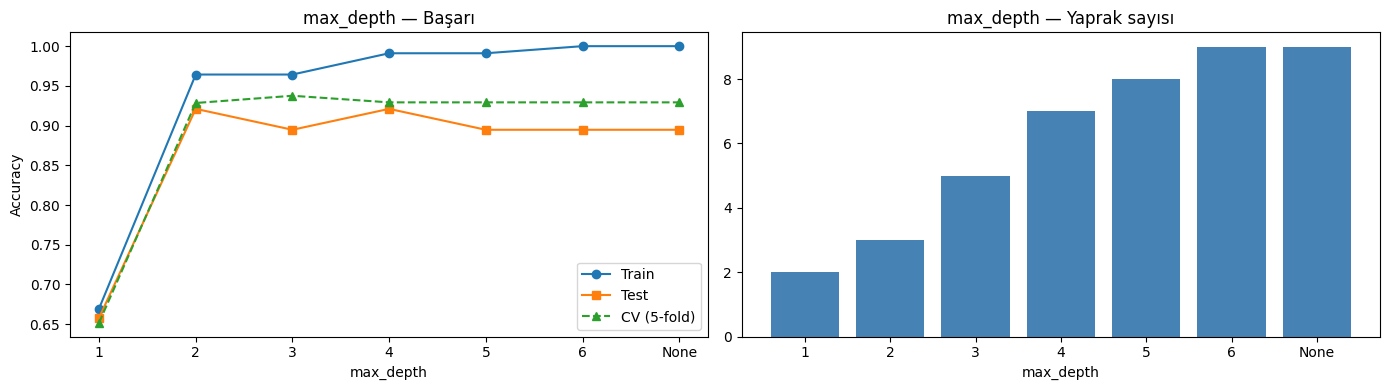

,max_depth,train_acc,test_acc,cv_acc,depth,leaves
0,1,0.669643,0.657895,0.651779,1,2
1,2,0.964286,0.921053,0.928458,2,3
2,3,0.964286,0.894737,0.937549,3,5
3,4,0.991071,0.921053,0.929249,4,7
4,5,0.991071,0.894737,0.929249,5,8
5,6,1.000000,0.894737,0.929249,6,9
6,None,1.000000,0.894737,0.929249,6,9


In [21]:
res_depth = evaluate("max_depth", [1, 2, 3, 4, 5, 6, None])
plot_eval(res_depth, "max_depth", "max_depth")
res_depth

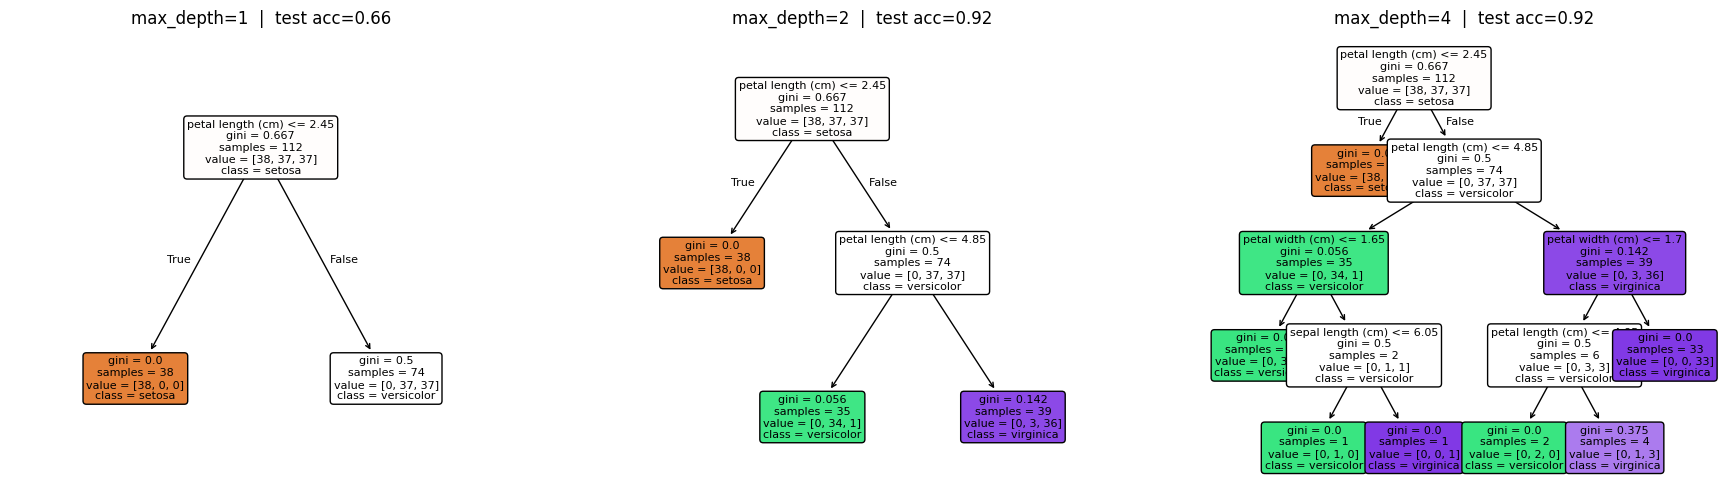

In [ ]:
# Aynı veri, farklı derinlikler -> ağacın nasıl büyüdüğünü yan yana görelim
fig, axes = plt.subplots(1, 3, figsize=(30, 7))
for ax, d in zip(axes, [1, 2, 4]):
    clf = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train)
    plot_tree(clf, feature_names=feature_names, class_names=class_names, filled=True, rounded=True, ax=ax, fontsize=8)
    ax.set_title(f"max_depth={d}  |  test acc={accuracy_score(y_test, clf.predict(X_test)):.2f}")
plt.show()

### 8.2 `min_samples_split` — Bölünmek için gereken minimum örnek
Bir düğümün bölünebilmesi için içinde **en az** bu kadar örnek olmalı. Büyüdükçe ağaç küçülür.  
(Tam sayı → adet, 0-1 arası ondalık → toplam örneğin oranı)

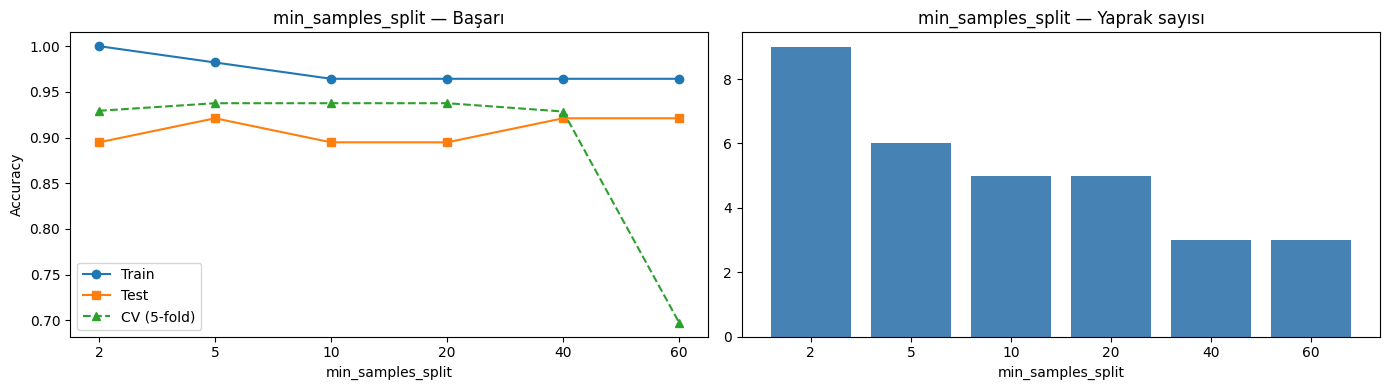

,min_samples_split,train_acc,test_acc,cv_acc,depth,leaves
0,2,1.000000,0.894737,0.929249,6,9
1,5,0.982143,0.921053,0.937549,4,6
2,10,0.964286,0.894737,0.937549,3,5
3,20,0.964286,0.894737,0.937549,3,5
4,40,0.964286,0.921053,0.928458,2,3
5,60,0.964286,0.921053,0.697233,2,3


In [23]:
res_split = evaluate("min_samples_split", [2, 5, 10, 20, 40, 60])
plot_eval(res_split, "min_samples_split", "min_samples_split")
res_split

### 8.3 `min_samples_leaf` — Yaprakta bulunması gereken minimum örnek
Bir bölünme, çocuklardan biri bu sayının altında kalacaksa **yapılmaz**. Tek örnekli, gürültüye dayalı yaprakları engeller → genellemeyi iyileştirir.

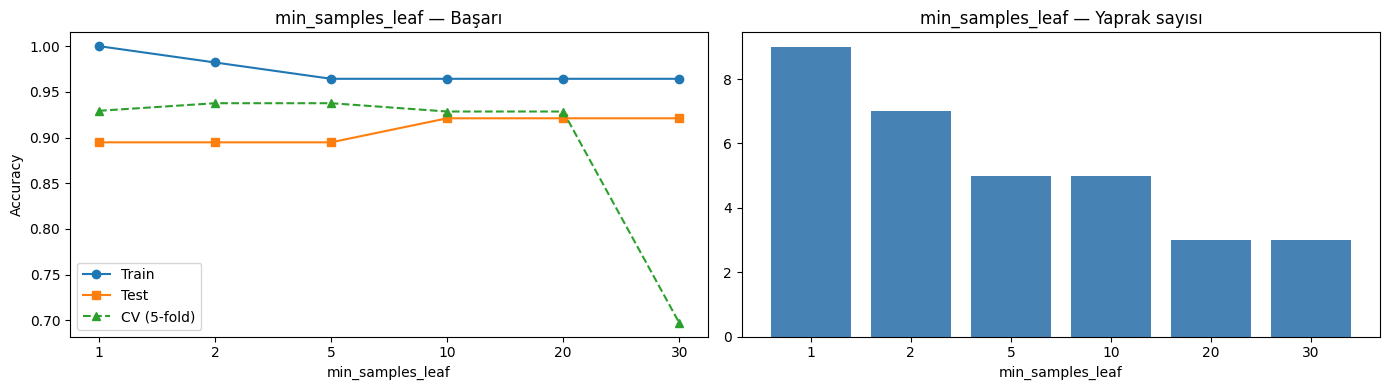

,min_samples_leaf,train_acc,test_acc,cv_acc,depth,leaves
0,1,1.000000,0.894737,0.929249,6,9
1,2,0.982143,0.894737,0.937549,5,7
2,5,0.964286,0.894737,0.937549,3,5
3,10,0.964286,0.921053,0.928458,3,5
4,20,0.964286,0.921053,0.928458,2,3
5,30,0.964286,0.921053,0.697233,2,3


In [24]:
res_leaf = evaluate("min_samples_leaf", [1, 2, 5, 10, 20, 30])
plot_eval(res_leaf, "min_samples_leaf", "min_samples_leaf")
res_leaf

### 8.4 `criterion` — Bölünme kalitesi ölçütü
- `gini` (varsayılan): hızlı, logaritma yok  
- `entropy` / `log_loss`: bilgi kazancı (information gain). sklearn'de `entropy` ve `log_loss` aynı sonucu verir.  
Pratikte çoğu zaman benzer ağaçlar üretirler.

In [25]:
res_crit = evaluate("criterion", ["gini", "entropy", "log_loss"], max_depth=3)
res_crit

,criterion,train_acc,test_acc,cv_acc,depth,leaves
0,gini,0.964286,0.894737,0.937549,3,5
1,entropy,0.964286,0.894737,0.928458,3,5
2,log_loss,0.964286,0.894737,0.928458,3,5


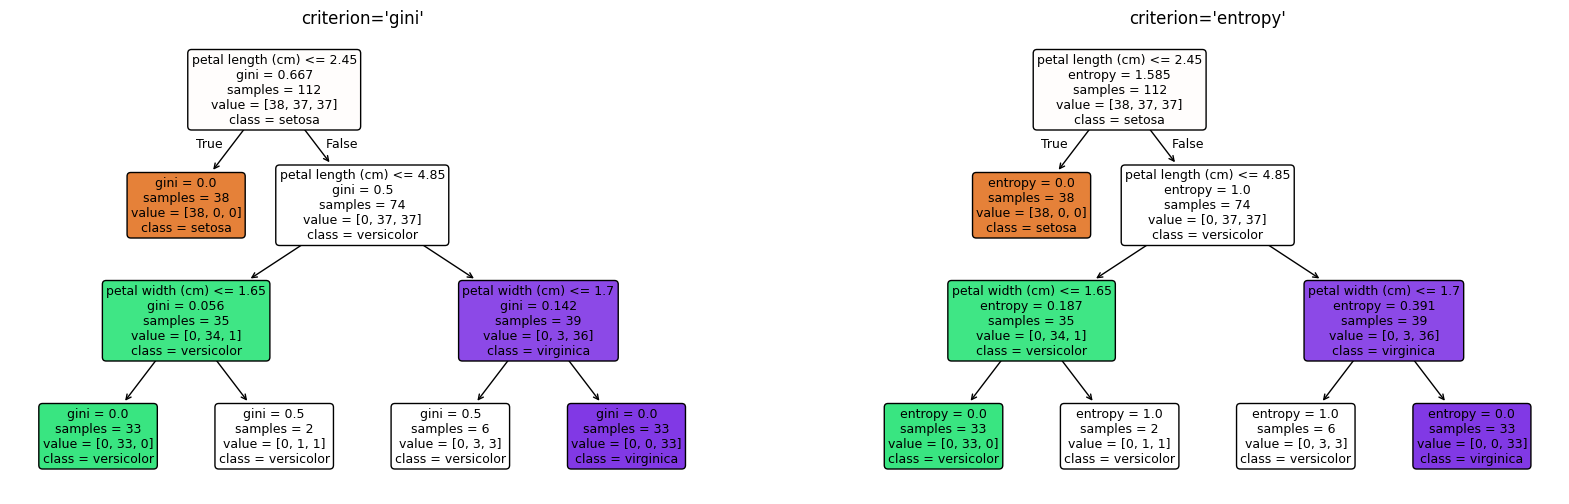

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(20, 6))
for ax, c in zip(axes, ["gini", "entropy"]):
    clf = DecisionTreeClassifier(criterion=c, max_depth=3, random_state=RANDOM_STATE).fit(X_train, y_train)
    plot_tree(clf, feature_names=feature_names, class_names=class_names, filled=True, rounded=True, ax=ax, fontsize=9)
    ax.set_title(f"criterion='{c}'")   # kutulardaki safsızlık değeri artık gini yerine entropy olarak görünür
plt.show()

### 8.5 `max_features` — Her bölünmede denenen özellik sayısı
- `None`: tüm özellikler denenir (varsayılan)  
- `"sqrt"`, `"log2"`, tam sayı, oran: her düğümde **rastgele seçilen** bir alt küme denenir  
Ağaca rastgelelik katar; tek ağaçta genelde başarıyı düşürür ama Random Forest'ın temel fikridir.

### 8.6 `splitter` — Eşik seçme stratejisi
- `"best"`: tüm eşikler arasından en iyisi  
- `"random"`: her özellik için rastgele eşikler, en iyisi seçilir → daha hızlı, daha rastgele

In [27]:
res_mf = evaluate("max_features", [None, "sqrt", "log2", 1, 2, 3], max_depth=3)
res_mf

,max_features,train_acc,test_acc,cv_acc,depth,leaves
0,None,0.964286,0.894737,0.937549,3,5
1,sqrt,0.964286,0.947368,0.955336,3,5
2,log2,0.964286,0.947368,0.955336,3,5
3,1,0.946429,0.815789,0.928854,3,6
4,2,0.964286,0.947368,0.955336,3,5
5,3,0.982143,0.973684,0.946245,3,5


In [28]:
res_splitter = evaluate("splitter", ["best", "random"], max_depth=3)
res_splitter

,splitter,train_acc,test_acc,cv_acc,depth,leaves
0,best,0.964286,0.894737,0.937549,3,5
1,random,0.964286,0.947368,0.937945,3,5


### 8.7 `max_leaf_nodes` ve `min_impurity_decrease`
- `max_leaf_nodes`: en fazla kaç yaprak olacağı. Ağaç **en iyi bölünmeden başlayarak** (best-first) büyütülür.  
- `min_impurity_decrease`: bir bölünme safsızlığı en az bu kadar azaltmıyorsa yapılmaz.

In [29]:
res_mln = evaluate("max_leaf_nodes", [2, 3, 4, 5, 8, None])
res_mln

,max_leaf_nodes,train_acc,test_acc,cv_acc,depth,leaves
0,2,0.669643,0.657895,0.651779,1,2
1,3,0.964286,0.921053,0.928458,2,3
2,4,0.964286,0.894737,0.937549,3,4
3,5,0.982143,0.921053,0.937549,4,5
4,8,0.991071,0.947368,0.928854,5,8
5,None,1.000000,0.894737,0.929249,6,9


In [30]:
res_mid = evaluate("min_impurity_decrease", [0.0, 0.005, 0.01, 0.02, 0.05, 0.1])
res_mid

,min_impurity_decrease,train_acc,test_acc,cv_acc,depth,leaves
0,0.0,1.000000,0.894737,0.929249,6,9
1,0.005,0.991071,0.921053,0.929249,4,7
2,0.01,0.982143,0.921053,0.937549,4,5
3,0.02,0.964286,0.894737,0.937549,3,4
4,0.05,0.964286,0.921053,0.928458,2,3
5,0.1,0.964286,0.921053,0.928458,2,3


### 8.8 `ccp_alpha` — Cost Complexity Pruning (Sonradan Budama)
Önce ağaç tamamen büyütülür, sonra şu maliyeti minimize edecek şekilde dallar budanır:

$$R_\alpha(T) = R(T) + \alpha \cdot |T|$$

$R(T)$: yaprakların toplam safsızlığı, $|T|$: yaprak sayısı.  
α büyüdükçe karmaşık ağaçlar cezalandırılır → ağaç küçülür. `cost_complexity_pruning_path` bize anlamlı α değerlerini verir.

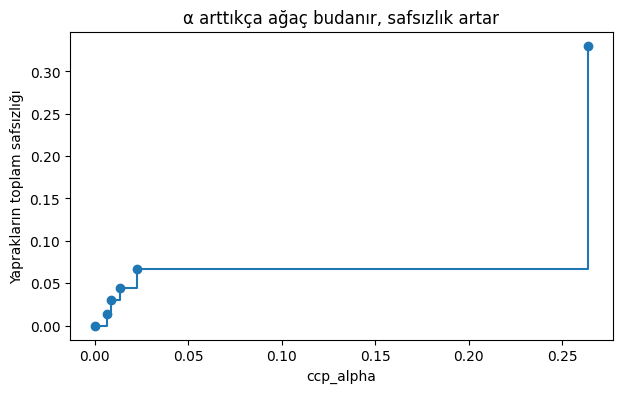

In [31]:
path = DecisionTreeClassifier(random_state=RANDOM_STATE).cost_complexity_pruning_path(X_train, y_train)
ccp_alphas, impurities = path.ccp_alphas, path.impurities

plt.figure(figsize=(7, 4))
plt.plot(ccp_alphas[:-1], impurities[:-1], "o-", drawstyle="steps-post")
plt.xlabel("ccp_alpha"); plt.ylabel("Yaprakların toplam safsızlığı")
plt.title("α arttıkça ağaç budanır, safsızlık artar")
plt.show()

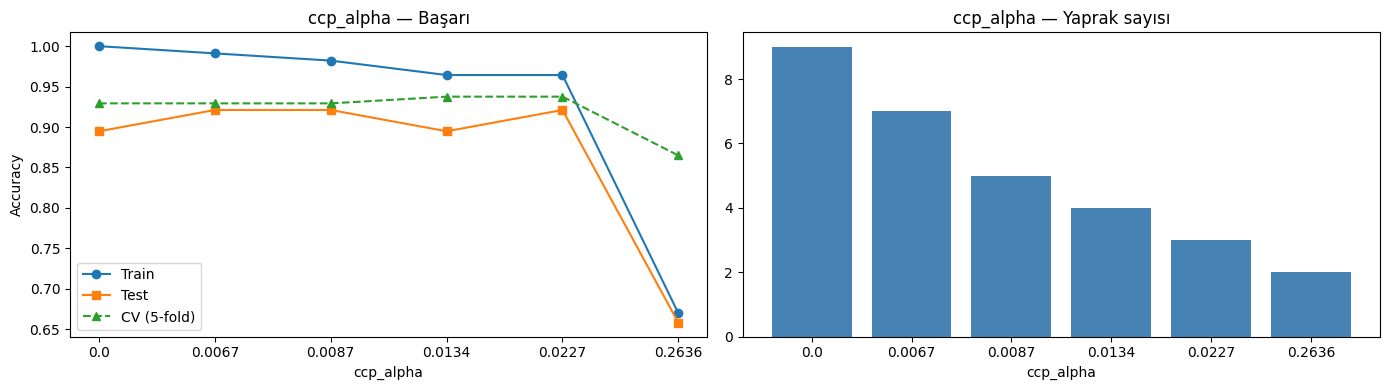

,ccp_alpha,train_acc,test_acc,cv_acc,depth,leaves
0,0.0,1.000000,0.894737,0.929249,6,9
1,0.0067,0.991071,0.921053,0.929249,4,7
2,0.0087,0.982143,0.921053,0.929249,4,5
3,0.0134,0.964286,0.894737,0.937549,3,4
4,0.0227,0.964286,0.921053,0.937549,2,3
5,0.2636,0.669643,0.657895,0.864822,1,2


In [32]:
# Son alfa değeri ağacı tek düğüme indirir (sadece kök), onu dışarıda bırakıyoruz
res_ccp = evaluate("ccp_alpha", np.round(ccp_alphas[:-1], 4))
plot_eval(res_ccp, "ccp_alpha", "ccp_alpha")
res_ccp

## 9. Karar Sınırları (Decision Boundary)
Karar ağacı uzayı **eksenlere paralel dikdörtgenlere** böler (her soru tek bir özellik üzerinde olduğu için).  
Görselleştirebilmek için sadece 2 özellik (petal length, petal width) kullanıyoruz.

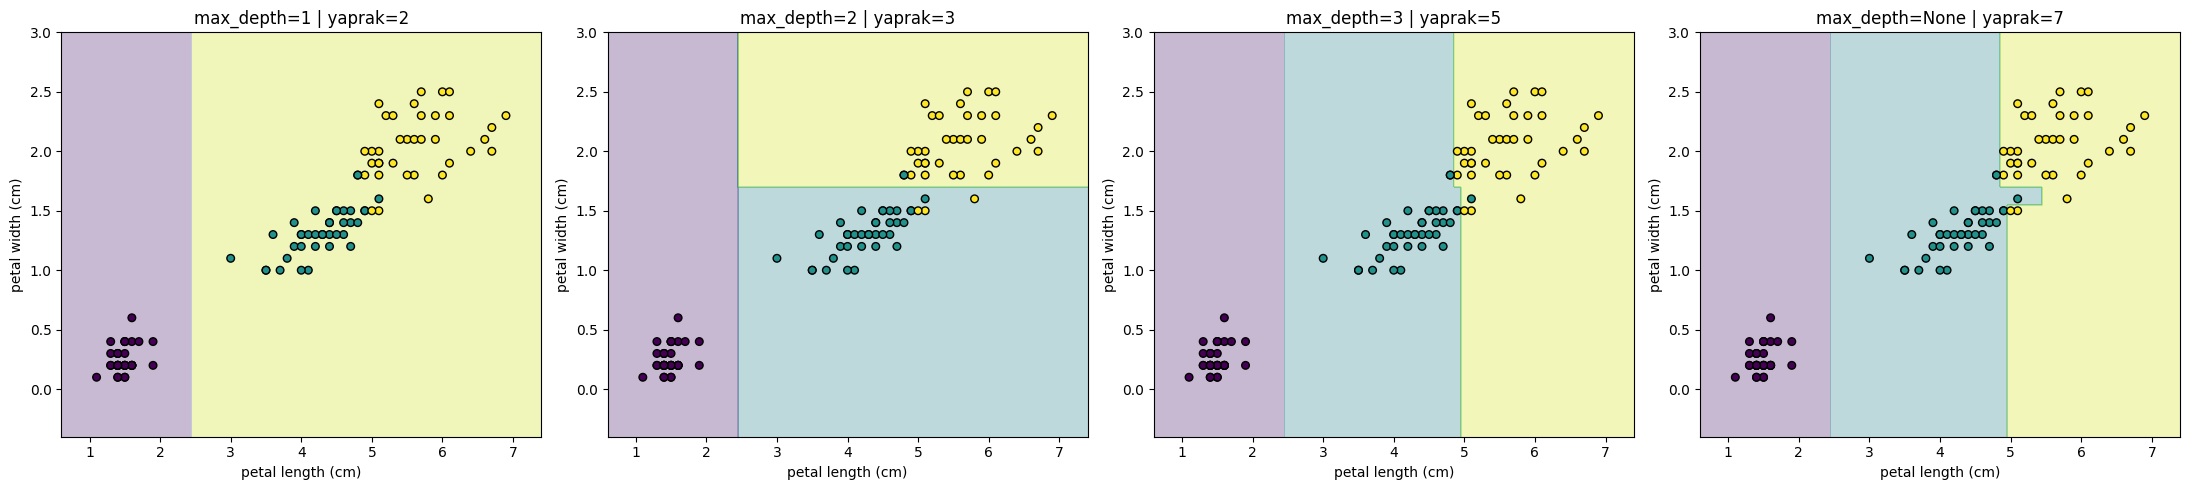

In [33]:
two_feats = ["petal length (cm)", "petal width (cm)"]
X2_train = X_train[two_feats].values

# Grafik için ızgara (grid) oluşturuyoruz; her noktanın sınıfını modele tahmin ettireceğiz
x_min, x_max = X2_train[:, 0].min() - 0.5, X2_train[:, 0].max() + 0.5
y_min, y_max = X2_train[:, 1].min() - 0.5, X2_train[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, d in zip(axes, [1, 2, 3, None]):
    clf = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X2_train, y_train)
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")
    ax.scatter(X2_train[:, 0], X2_train[:, 1], c=y_train, cmap="viridis", edgecolor="k", s=30)
    ax.set_title(f"max_depth={d} | yaprak={clf.get_n_leaves()}")
    ax.set_xlabel(two_feats[0]); ax.set_ylabel(two_feats[1])
plt.tight_layout(); plt.show()
# max_depth=None'da tek tek noktalar için küçük kutular oluşuyor -> overfitting'in görsel karşılığı

## 10. Hiperparametre Optimizasyonu (GridSearchCV)
Parametreleri tek tek değil, **kombinasyon halinde** deneyip cross-validation ile en iyisini seçiyoruz.  
Test seti bu aşamada **kullanılmaz**; sadece en sonda bir kez değerlendirme için kullanılır.

In [34]:
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [2, 3, 4, 5, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": [None, "sqrt"],
    "ccp_alpha": [0.0, 0.01, 0.02],
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid,
    cv=5,                 # 5-fold cross validation
    scoring="accuracy",
    n_jobs=-1             # tüm CPU çekirdeklerini kullan
)
grid.fit(X_train, y_train)

print("Denenen kombinasyon sayısı:", len(grid.cv_results_["params"]))
print("En iyi parametreler:", grid.best_params_)
print("En iyi CV skoru    :", round(grid.best_score_, 4))

Denenen kombinasyon sayısı: 720
En iyi parametreler: {'ccp_alpha': 0.0, 'criterion': 'gini', 'max_depth': 2, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2}
En iyi CV skoru    : 0.9553


In [35]:
# En iyi 10 kombinasyon -> birçok kombinasyonun aynı skoru verdiğini görürüz (iris küçük ve kolay bir veri seti)
cv_res = pd.DataFrame(grid.cv_results_)
cv_res[["params", "mean_test_score", "std_test_score", "rank_test_score"]] \
    .sort_values("rank_test_score").head(10)

,params,mean_test_score,std_test_score,rank_test_score
479,"{'ccp_alpha': 0.01, 'criterion': 'entropy', 'm...",0.955336,0.028764,1
252,"{'ccp_alpha': 0.01, 'criterion': 'gini', 'max_...",0.955336,0.028764,1
239,"{'ccp_alpha': 0.0, 'criterion': 'entropy', 'ma...",0.955336,0.028764,1
431,"{'ccp_alpha': 0.01, 'criterion': 'entropy', 'm...",0.955336,0.028764,1
430,"{'ccp_alpha': 0.01, 'criterion': 'entropy', 'm...",0.955336,0.028764,1
429,"{'ccp_alpha': 0.01, 'criterion': 'entropy', 'm...",0.955336,0.028764,1
428,"{'ccp_alpha': 0.01, 'criterion': 'entropy', 'm...",0.955336,0.028764,1
427,"{'ccp_alpha': 0.01, 'criterion': 'entropy', 'm...",0.955336,0.028764,1
426,"{'ccp_alpha': 0.01, 'criterion': 'entropy', 'm...",0.955336,0.028764,1
253,"{'ccp_alpha': 0.01, 'criterion': 'gini', 'max_...",0.955336,0.028764,1


## 11. Final Model ve Bir Örneğin Ağaçta İzlediği Yol

Test accuracy: 0.9473684210526315
------------------------------------------------------------
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        12
  versicolor       0.92      0.92      0.92        13
   virginica       0.92      0.92      0.92        13

    accuracy                           0.95        38
   macro avg       0.95      0.95      0.95        38
weighted avg       0.95      0.95      0.95        38



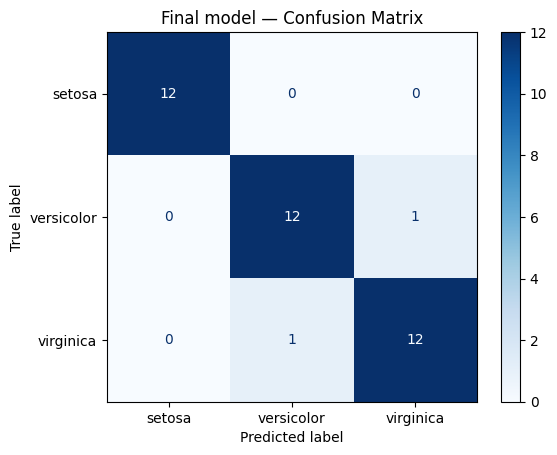

In [36]:
best_tree = grid.best_estimator_
y_pred_best = best_tree.predict(X_test)

print("Test accuracy:", accuracy_score(y_test, y_pred_best))
print("-" * 60)
print(classification_report(y_test, y_pred_best, target_names=class_names))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best, display_labels=class_names, cmap="Blues")
plt.title("Final model — Confusion Matrix")
plt.show()

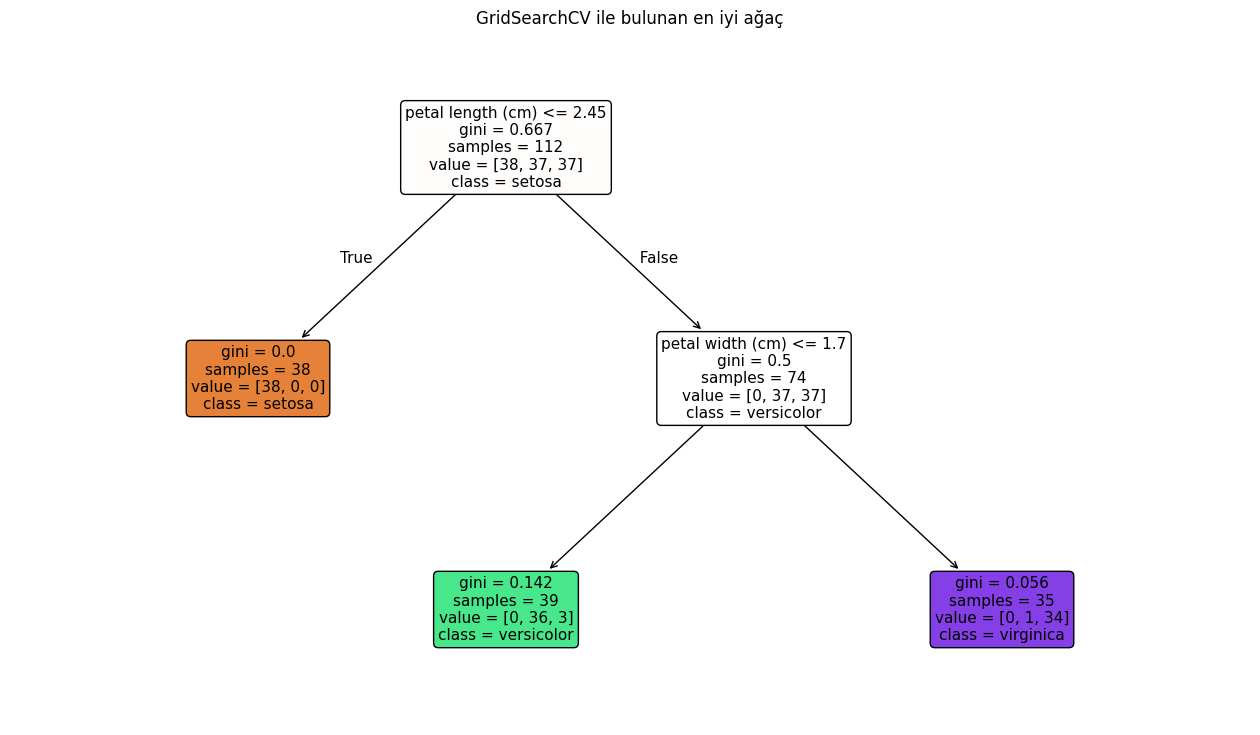

In [37]:
plt.figure(figsize=(16, 9))
plot_tree(best_tree, feature_names=feature_names, class_names=class_names, filled=True, rounded=True, fontsize=11)
plt.title("GridSearchCV ile bulunan en iyi ağaç")
plt.show()

In [38]:
# Yeni bir çiçek ölçümü verip modelin nasıl karar verdiğini adım adım izleyelim
sample = pd.DataFrame([[6.1, 2.8, 4.7, 1.4]], columns=feature_names)

pred = best_tree.predict(sample)[0]
proba = best_tree.predict_proba(sample)[0]   # olasılık = ulaşılan yapraktaki sınıf oranları
print("Tahmin:", class_names[pred])
print("Olasılıklar:", {c: round(float(p), 3) for c, p in zip(class_names, proba)})
print()

# decision_path -> örneğin uğradığı düğümler; apply -> ulaştığı yaprak
node_path = best_tree.decision_path(sample).indices
leaf_id = best_tree.apply(sample)[0]
bt = best_tree.tree_

for node in node_path:
    if node == leaf_id:
        print(f"Düğüm {node}: YAPRAK -> value={bt.value[node][0].round(2)} -> sınıf = {class_names[pred]}")
        break
    f, thr = bt.feature[node], bt.threshold[node]
    val = sample.iloc[0, f]
    direction = "≤" if val <= thr else ">"
    side = "sol" if val <= thr else "sağ"
    print(f"Düğüm {node}: {feature_names[f]} = {val} {direction} {thr:.2f}  -> {side} dala git")

Tahmin: versicolor
Olasılıklar: {np.str_('setosa'): 0.0, np.str_('versicolor'): 0.923, np.str_('virginica'): 0.077}

Düğüm 0: petal length (cm) = 4.7 > 2.45  -> sağ dala git
Düğüm 2: petal width (cm) = 1.4 ≤ 1.70  -> sol dala git
Düğüm 3: YAPRAK -> value=[0.   0.92 0.08] -> sınıf = versicolor


## 12. Özet: DecisionTreeClassifier Parametreleri

| Parametre | Varsayılan | Ne yapar? | Artırınca / değiştirince |
|---|---|---|---|
| `criterion` | `"gini"` | Bölünme kalitesini ölçer (`gini`, `entropy`, `log_loss`) | Genelde benzer ağaçlar |
| `splitter` | `"best"` | Eşik seçimi: en iyi mi, rastgele mi | `random` → daha hızlı, daha değişken |
| `max_depth` | `None` | Maksimum derinlik | Artarsa karmaşıklık ↑, overfitting riski ↑ |
| `min_samples_split` | `2` | Bölünme için min. örnek | Artarsa ağaç küçülür |
| `min_samples_leaf` | `1` | Yapraktaki min. örnek | Artarsa ağaç küçülür, daha pürüzsüz sınırlar |
| `max_features` | `None` | Her bölünmede denenen özellik sayısı | Azalırsa rastgelelik ↑ |
| `max_leaf_nodes` | `None` | Maksimum yaprak sayısı | Azalırsa ağaç küçülür |
| `min_impurity_decrease` | `0.0` | Bölünme için gereken min. safsızlık düşüşü | Artarsa zayıf bölünmeler yapılmaz |
| `ccp_alpha` | `0.0` | Sonradan budama gücü | Artarsa ağaç budanır |
| `class_weight` | `None` | Sınıflara ağırlık (dengesiz veri için `"balanced"`) | Azınlık sınıfa önem ↑ |
| `random_state` | `None` | Rastgeleliği sabitler | Tekrarlanabilir sonuç |

**Önemli noktalar**
- Karar ağaçları ölçeklemeye ihtiyaç duymaz, yorumlanabilirliği yüksektir.
- Sınırlanmazsa kolayca overfit olur → `max_depth`, `min_samples_leaf`, `ccp_alpha` ile kontrol edilir.
- Veri küçük değişikliklere hassastır (yüksek varyans) → bu sorun Random Forest / Gradient Boosting gibi ensemble yöntemlerle çözülür.